In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

np.random.seed(42)

In [2]:
n = 1000

products = [
    "Laptop",
    "Smartphone",
    "Headphones",
    "Keyboard",
    "Mouse",
    "Monitor",
    "Tablet",
    "Smartwatch"
]

categories = {
    "Laptop": "Electronics",
    "Smartphone": "Electronics",
    "Headphones": "Accessories",
    "Keyboard": "Accessories",
    "Mouse": "Accessories",
    "Monitor": "Electronics",
    "Tablet": "Electronics",
    "Smartwatch": "Wearables"
}

regions = ["North", "South", "East", "West"]

suppliers = [
    "Supplier A",
    "Supplier B",
    "Supplier C",
    "Supplier D",
    "Supplier E"
]

df = pd.DataFrame({
    "Order_ID": range(1, n + 1),

    "Order_Date": pd.date_range(
        start="2023-01-01",
        periods=n,
        freq="D"
    ),

    "Product": np.random.choice(products, n),

    "Region": np.random.choice(regions, n),

    "Supplier": np.random.choice(suppliers, n),

    "Units_Sold": np.random.randint(10, 200, n),

    "Inventory_Level": np.random.randint(0, 1000, n),

    "Lead_Time_Days": np.random.randint(1, 30, n),

    "Delivery_Days": np.random.randint(1, 40, n),

    "Cost_Per_Unit": np.random.randint(50, 1000, n),

    "Selling_Price": np.random.randint(100, 1500, n)
})

df["Category"] = df["Product"].map(categories)

df["Revenue"] = (
    df["Units_Sold"] *
    df["Selling_Price"]
)

df["Total_Cost"] = (
    df["Units_Sold"] *
    df["Cost_Per_Unit"]
)

df["Profit"] = (
    df["Revenue"] -
    df["Total_Cost"]
)

df["Profit_Margin"] = (
    df["Profit"] /
    df["Revenue"] * 100
)

df.head()

,Order_ID,Order_Date,Product,Region,Supplier,Units_Sold,Inventory_Level,Lead_Time_Days,Delivery_Days,Cost_Per_Unit,Selling_Price,Category,Revenue,Total_Cost,Profit,Profit_Margin
0,1,2023-01-01,Tablet,South,Supplier D,43,67,25,27,741,1226,Electronics,52718,31863,20855,39.559543
1,2,2023-01-02,Keyboard,East,Supplier C,17,68,19,23,536,1133,Accessories,19261,9112,10149,52.691968
2,3,2023-01-03,Mouse,North,Supplier E,196,164,4,24,934,682,Accessories,133672,183064,-49392,-36.950147
3,4,2023-01-04,Tablet,North,Supplier A,186,488,17,9,221,1213,Electronics,225618,41106,184512,81.780709
4,5,2023-01-05,Headphones,North,Supplier E,88,304,9,35,999,325,Accessories,28600,87912,-59312,-207.384615


In [3]:
df.to_csv("supply_chain_data.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [4]:
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Order_ID         1000 non-null   int64         
 1   Order_Date       1000 non-null   datetime64[ns]
 2   Product          1000 non-null   object        
 3   Region           1000 non-null   object        
 4   Supplier         1000 non-null   object        
 5   Units_Sold       1000 non-null   int64         
 6   Inventory_Level  1000 non-null   int64         
 7   Lead_Time_Days   1000 non-null   int64         
 8   Delivery_Days    1000 non-null   int64         
 9   Cost_Per_Unit    1000 non-null   int64         
 10  Selling_Price    1000 non-null   int64         
 11  Category         1000 non-null   object        
 12  Revenue          1000 non-null   int64         
 13  Total_Cost       1000 non-null   int64         
 14  Profit           1000 non-null   int64   

In [5]:
df = df.drop_duplicates()

In [6]:
total_revenue = df["Revenue"].sum()

total_profit = df["Profit"].sum()

total_units_sold = df["Units_Sold"].sum()

average_inventory = df["Inventory_Level"].mean()

average_lead_time = df["Lead_Time_Days"].mean()

print("TOTAL REVENUE:", round(total_revenue, 2))

print("TOTAL PROFIT:", round(total_profit, 2))

print("TOTAL UNITS SOLD:", total_units_sold)

print("AVERAGE INVENTORY:", round(average_inventory, 2))

print("AVERAGE LEAD TIME:", round(average_lead_time, 2), "days")

TOTAL REVENUE: 87811826
TOTAL PROFIT: 32112709
TOTAL UNITS SOLD: 108073
AVERAGE INVENTORY: 506.93
AVERAGE LEAD TIME: 15.51 days


In [7]:
product_revenue = (
    df.groupby("Product")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print(product_revenue)

Product
Keyboard      12379981
Smartwatch    12079264
Mouse         11819469
Laptop        11669732
Monitor       11019647
Tablet        10944050
Headphones     9506650
Smartphone     8393033
Name: Revenue, dtype: int64


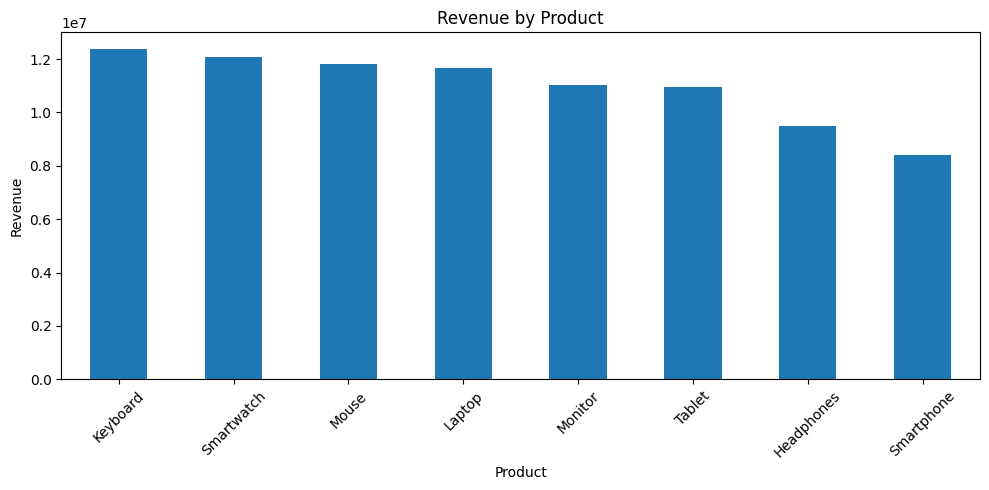

In [8]:
plt.figure(figsize=(10, 5))

product_revenue.plot(kind="bar")

plt.title("Revenue by Product")

plt.xlabel("Product")

plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [9]:
product_profit = (
    df.groupby("Product")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print(product_profit)

Product
Monitor       5199383
Keyboard      4695600
Mouse         4232404
Laptop        3936142
Smartwatch    3917469
Headphones    3906608
Tablet        3814862
Smartphone    2410241
Name: Profit, dtype: int64


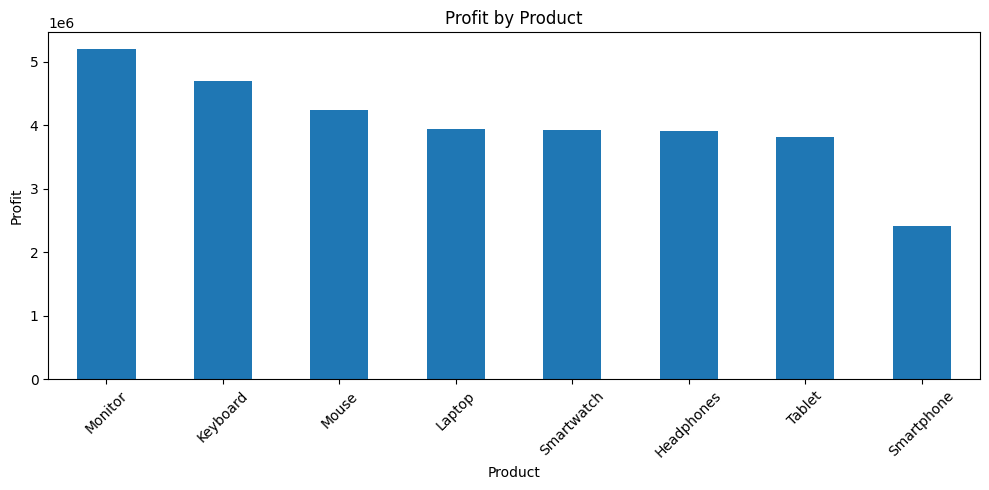

In [10]:
plt.figure(figsize=(10, 5))

product_profit.plot(kind="bar")

plt.title("Profit by Product")

plt.xlabel("Product")

plt.ylabel("Profit")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [11]:
regional_performance = (
    df.groupby("Region")
    .agg(
        Revenue=("Revenue", "sum"),
        Profit=("Profit", "sum"),
        Units_Sold=("Units_Sold", "sum")
    )
)

print(regional_performance)

         Revenue   Profit  Units_Sold
Region                               
East    23052578  9946621       28000
North   24188194  8795248       29732
South   23476188  7344593       28597
West    17094866  6026247       21744


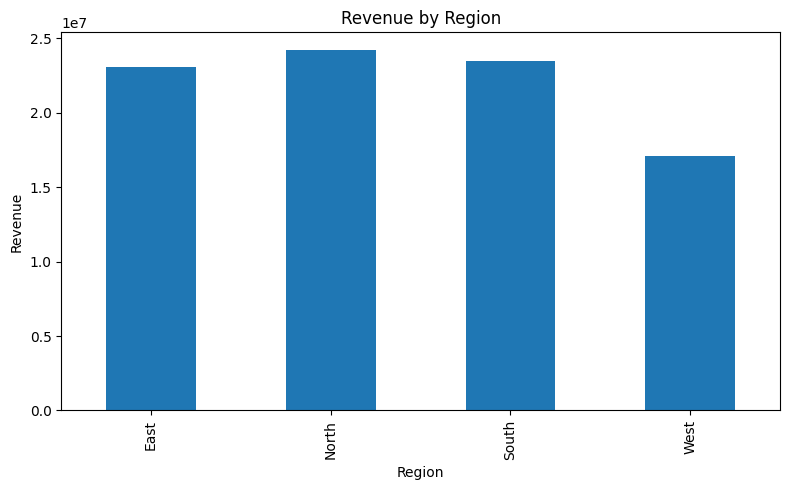

In [12]:
regional_performance["Revenue"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Revenue by Region")

plt.xlabel("Region")

plt.ylabel("Revenue")

plt.tight_layout()

plt.show()

In [13]:
supplier_performance = (
    df.groupby("Supplier")
    .agg(
        Average_Lead_Time=("Lead_Time_Days", "mean"),
        Average_Delivery_Time=("Delivery_Days", "mean"),
        Total_Revenue=("Revenue", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Average_Delivery_Time")
)

print(supplier_performance)

            Average_Lead_Time  Average_Delivery_Time  Total_Revenue  \
Supplier                                                              
Supplier D          16.028846              19.206731       18670163   
Supplier E          14.906542              19.570093       18880721   
Supplier C          15.832370              20.283237       14519415   
Supplier A          15.823834              20.393782       17219372   
Supplier B          15.056604              21.797170       18522155   

            Total_Profit  
Supplier                  
Supplier D       6494922  
Supplier E       7687482  
Supplier C       4200386  
Supplier A       6211726  
Supplier B       7518193  


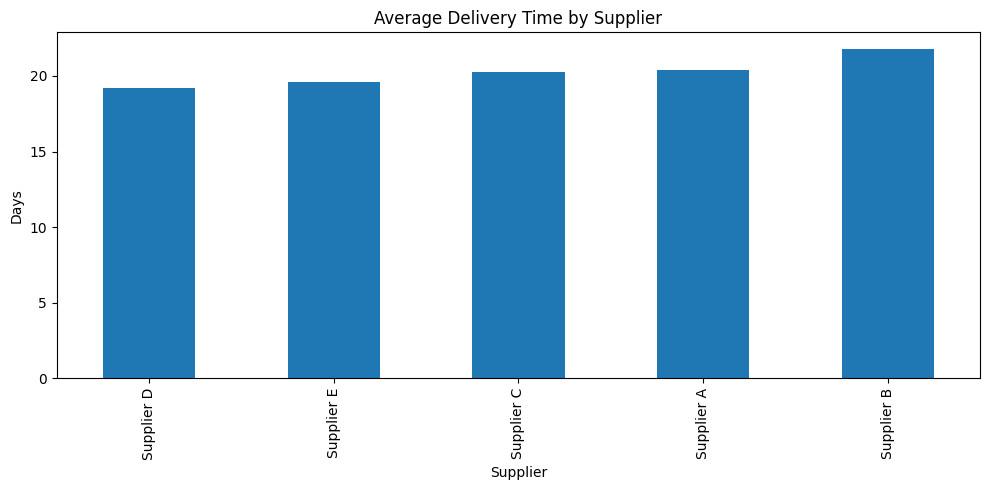

In [14]:
supplier_performance["Average_Delivery_Time"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Delivery Time by Supplier")

plt.xlabel("Supplier")

plt.ylabel("Days")

plt.tight_layout()

plt.show()

# Identify potential stockouts

In [15]:
low_stock = df[
    df["Inventory_Level"] < 100
]

print("Number of Low Stock Records:")

print(low_stock.shape[0])

low_stock.head()

Number of Low Stock Records:
90


,Order_ID,Order_Date,Product,Region,Supplier,Units_Sold,Inventory_Level,Lead_Time_Days,Delivery_Days,Cost_Per_Unit,Selling_Price,Category,Revenue,Total_Cost,Profit,Profit_Margin
0,1,2023-01-01,Tablet,South,Supplier D,43,67,25,27,741,1226,Electronics,52718,31863,20855,39.559543
1,2,2023-01-02,Keyboard,East,Supplier C,17,68,19,23,536,1133,Accessories,19261,9112,10149,52.691968
44,45,2023-02-14,Keyboard,South,Supplier E,147,98,4,13,269,443,Accessories,65121,39543,25578,39.277652
64,65,2023-03-06,Tablet,South,Supplier A,123,63,19,10,974,267,Electronics,32841,119802,-86961,-264.794007
65,66,2023-03-07,Smartphone,East,Supplier E,19,90,6,24,172,1053,Electronics,20007,3268,16739,83.665717


In [16]:
low_stock_products = (
    low_stock["Product"]
    .value_counts()
)

print(low_stock_products)

Product
Mouse         14
Headphones    14
Smartphone    12
Keyboard      12
Laptop        12
Tablet        10
Smartwatch     8
Monitor        8
Name: count, dtype: int64


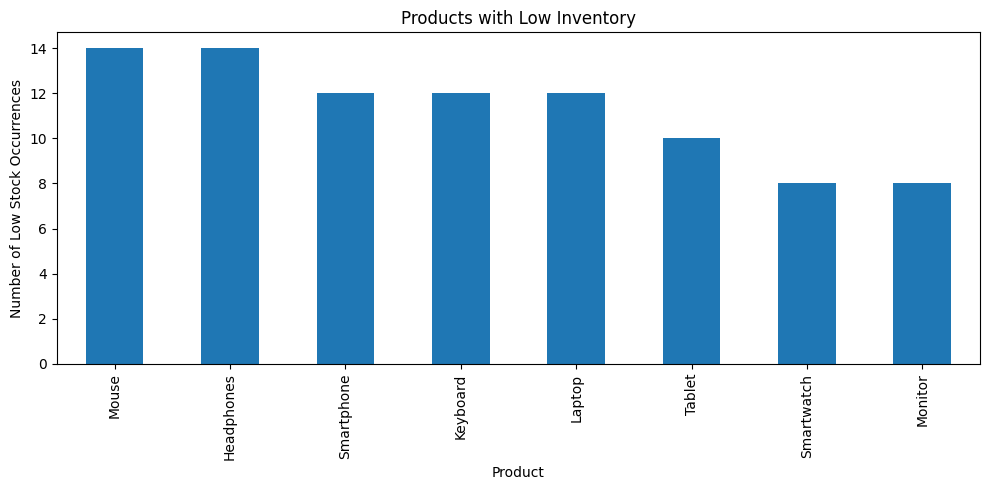

In [17]:
low_stock_products.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Products with Low Inventory")

plt.xlabel("Product")

plt.ylabel("Number of Low Stock Occurrences")

plt.tight_layout()

plt.show()

In [18]:
product_inventory = (
    df.groupby("Product")
    .agg(
        Total_Units_Sold=("Units_Sold", "sum"),
        Average_Inventory=("Inventory_Level", "mean")
    )
)

product_inventory["Inventory_Turnover"] = (
    product_inventory["Total_Units_Sold"] /
    product_inventory["Average_Inventory"]
)

product_inventory = product_inventory.sort_values(
    "Inventory_Turnover",
    ascending=False
)

print(product_inventory)

            Total_Units_Sold  Average_Inventory  Inventory_Turnover
Product                                                            
Keyboard               15380         473.917808           32.452885
Laptop                 14336         508.187970           28.210034
Smartwatch             15047         546.082090           27.554465
Mouse                  13840         509.536000           27.161967
Monitor                12781         483.973451           26.408473
Tablet                 13661         524.151261           26.063087
Smartphone             11637         500.307692           23.259686
Headphones             11391         510.495575           22.313612


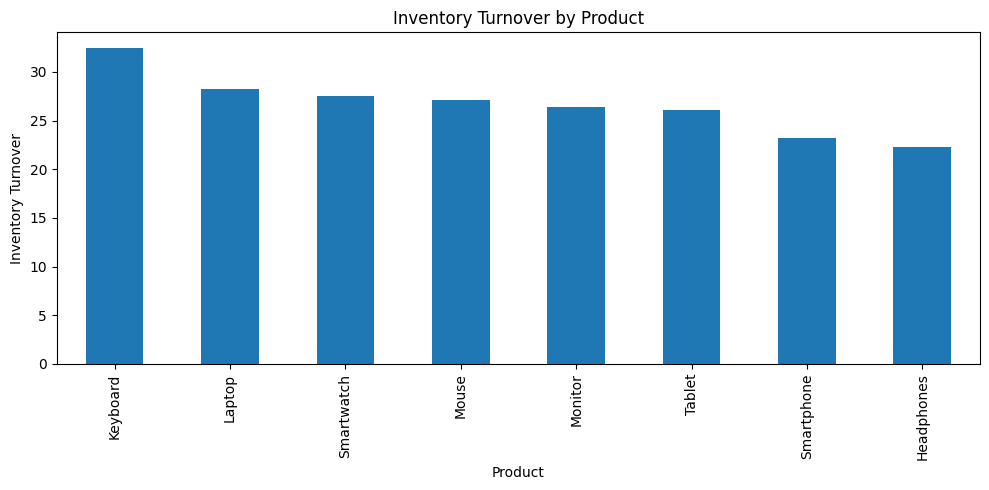

In [19]:
product_inventory["Inventory_Turnover"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Inventory Turnover by Product")

plt.xlabel("Product")

plt.ylabel("Inventory Turnover")

plt.tight_layout()

plt.show()

In [20]:
df["Delayed"] = (
    df["Delivery_Days"] >
    df["Lead_Time_Days"]
)

In [21]:
delayed_orders = df["Delayed"].value_counts()

print(delayed_orders)

Delayed
True     600
False    400
Name: count, dtype: int64


In [22]:
supplier_delay = (
    df.groupby("Supplier")["Delayed"]
    .mean() * 100
)

supplier_delay = supplier_delay.sort_values(
    ascending=False
)

print(supplier_delay)

Supplier
Supplier B    63.679245
Supplier E    60.747664
Supplier C    59.537572
Supplier D    58.173077
Supplier A    57.512953
Name: Delayed, dtype: float64


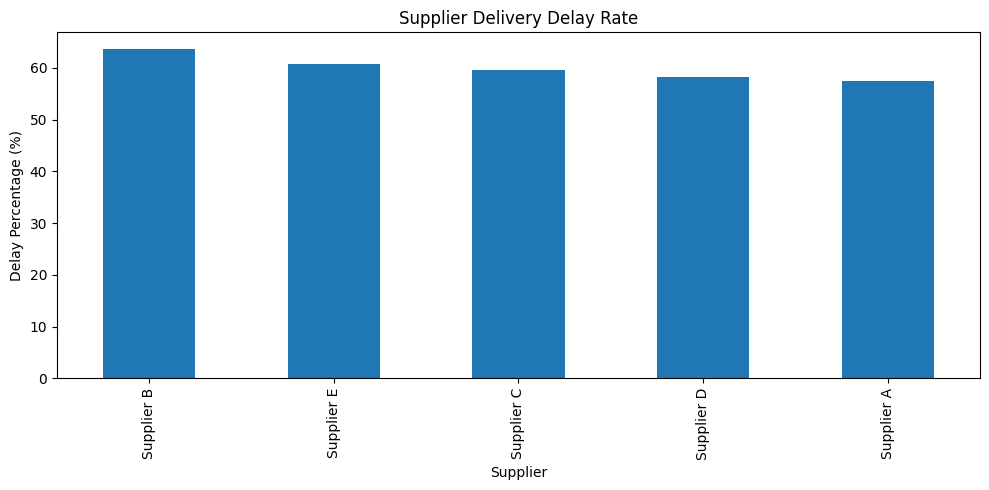

In [23]:
supplier_delay.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Supplier Delivery Delay Rate")

plt.xlabel("Supplier")

plt.ylabel("Delay Percentage (%)")

plt.tight_layout()

plt.show()

# Profit margin by product

In [24]:
profit_margin = (
    df.groupby("Product")["Profit_Margin"]
    .mean()
    .sort_values(ascending=False)
)

print(profit_margin)

Product
Monitor       21.536319
Mouse         17.627826
Keyboard       9.018734
Tablet         2.802718
Smartwatch    -0.679932
Headphones    -2.075013
Smartphone    -9.821044
Laptop        -9.976636
Name: Profit_Margin, dtype: float64


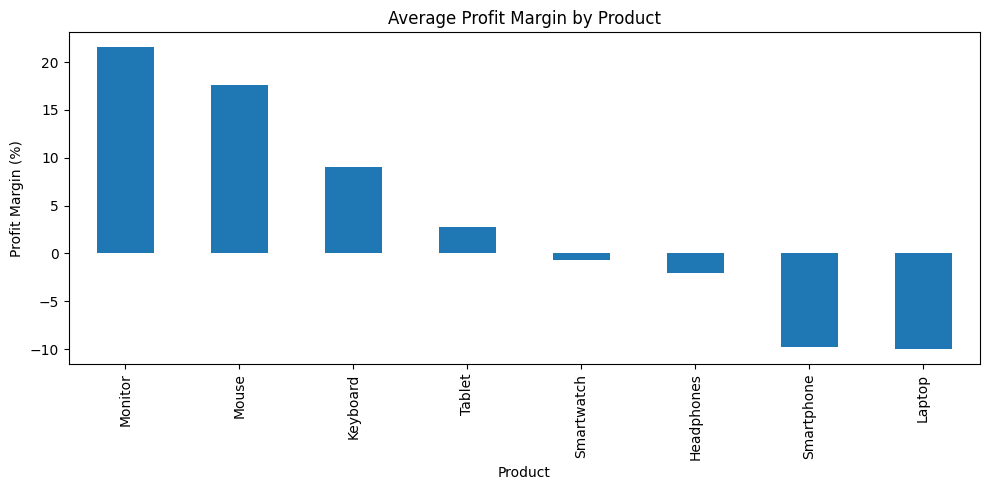

In [25]:
profit_margin.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Profit Margin by Product")

plt.xlabel("Product")

plt.ylabel("Profit Margin (%)")

plt.tight_layout()

plt.show()

# SQL Analysis

In [26]:
conn = sqlite3.connect("supply_chain.db")

df.to_sql(
    "supply_chain",
    conn,
    if_exists="replace",
    index=False
)

1000

In [27]:
query = """

SELECT
    Product,
    SUM(Revenue) AS Total_Revenue

FROM supply_chain

GROUP BY Product

ORDER BY Total_Revenue DESC

LIMIT 5;

"""

pd.read_sql_query(query, conn)

,Product,Total_Revenue
0,Keyboard,12379981
1,Smartwatch,12079264
2,Mouse,11819469
3,Laptop,11669732
4,Monitor,11019647


In [28]:
query = """

SELECT
    Supplier,

    AVG(Delivery_Days) AS Average_Delivery_Time,

    AVG(Lead_Time_Days) AS Average_Lead_Time,

    SUM(Revenue) AS Total_Revenue

FROM supply_chain

GROUP BY Supplier

ORDER BY Average_Delivery_Time;

"""

pd.read_sql_query(query, conn)

,Supplier,Average_Delivery_Time,Average_Lead_Time,Total_Revenue
0,Supplier D,19.206731,16.028846,18670163
1,Supplier E,19.570093,14.906542,18880721
2,Supplier C,20.283237,15.832370,14519415
3,Supplier A,20.393782,15.823834,17219372
4,Supplier B,21.797170,15.056604,18522155


In [29]:
query = """

SELECT
    Product,

    AVG(Inventory_Level) AS Average_Inventory,

    SUM(Units_Sold) AS Total_Units_Sold

FROM supply_chain

GROUP BY Product

HAVING AVG(Inventory_Level) < 500

ORDER BY Average_Inventory;

"""

pd.read_sql_query(query, conn)

,Product,Average_Inventory,Total_Units_Sold
0,Keyboard,473.917808,15380
1,Monitor,483.973451,12781


# Final executive dashboard

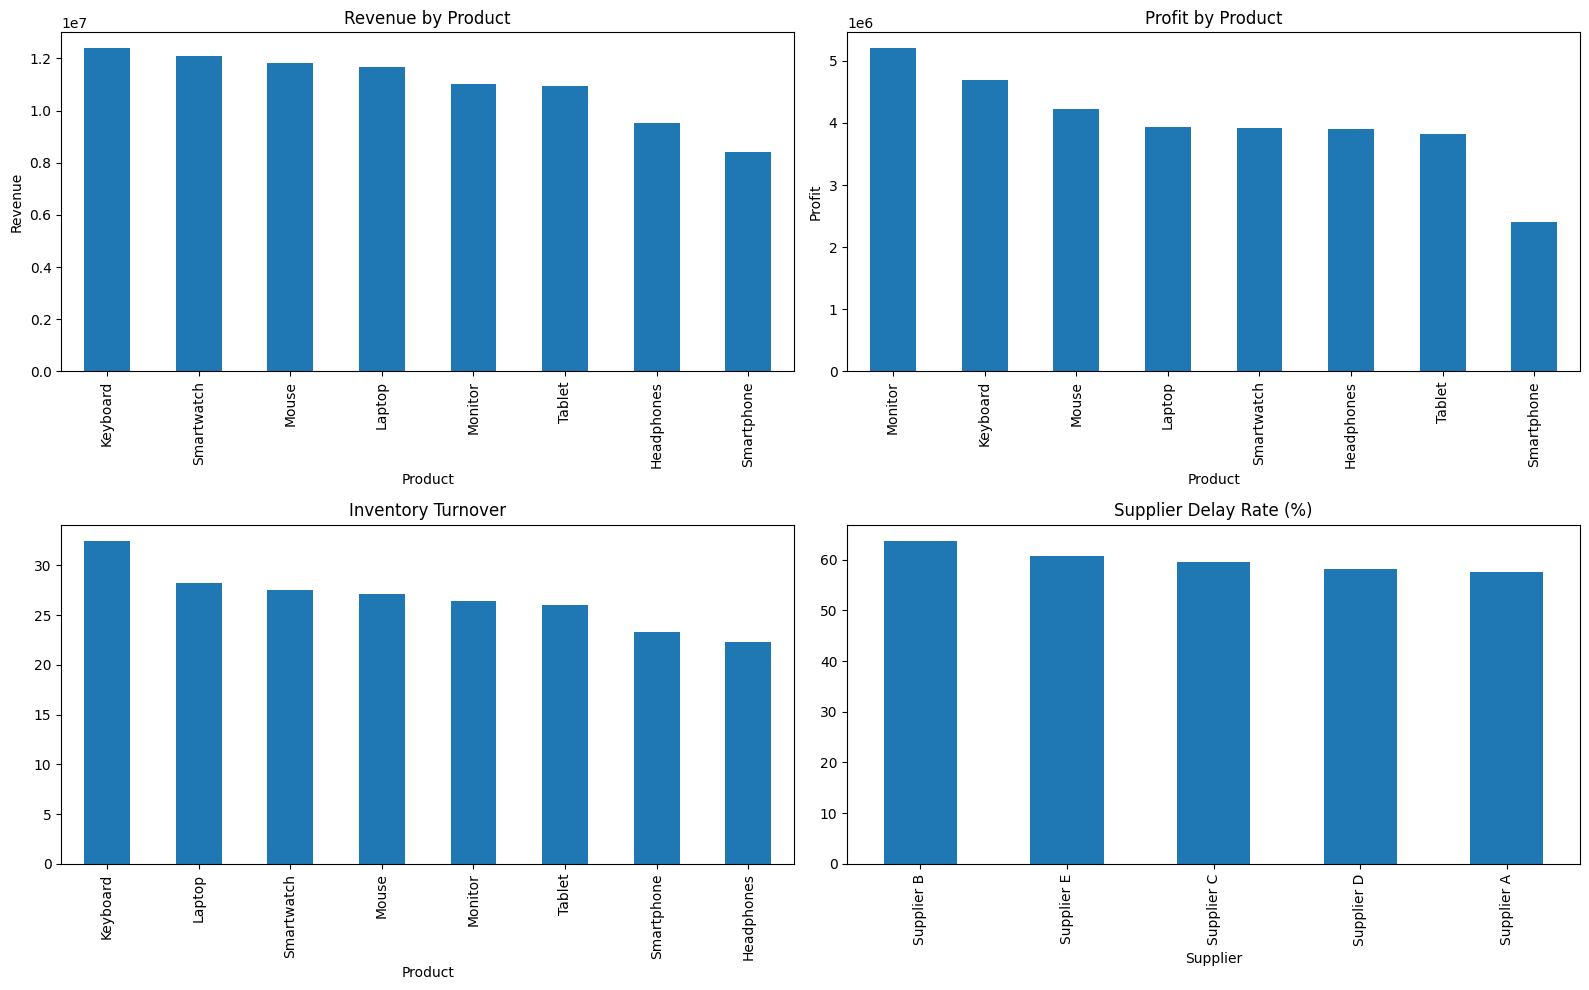

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Revenue by Product
product_revenue.plot(
    kind="bar",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Revenue by Product")
axes[0, 0].set_ylabel("Revenue")


# Profit by Product
product_profit.plot(
    kind="bar",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Profit by Product")
axes[0, 1].set_ylabel("Profit")


# Inventory Turnover
product_inventory["Inventory_Turnover"].plot(
    kind="bar",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Inventory Turnover")


# Supplier Delay Rate
supplier_delay.plot(
    kind="bar",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Supplier Delay Rate (%)")


plt.tight_layout()

plt.show()

In [31]:
df.to_csv(
    "supply_chain_final.csv",
    index=False
)